11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28, 1)
Epoch 1/10 completed | Generator Loss: 1.4206 | Discriminator Loss: 0.5105
Epoch 2/10 completed | Generator Loss: 2.5854 | Discriminator Loss: 0.4305
Epoch 3/10 completed | Generator Loss: 2.2784 | Discriminator Loss: 0.5910
Epoch 4/10 completed | Generator Loss: 2.4447 | Discriminator Loss: 0.6428
Epoch 5/10 completed | Generator Loss: 1.9192 | Discriminator Loss: 0.9347
Epoch 6/10 completed | Generator Loss: 1.8592 | Discriminator Loss: 0.7036
Epoch 7/10 completed | Generator Loss: 1.8880 | Discriminator Loss: 0.6993
Epoch 8/10 completed | Generator Loss: 1.8185 | Discriminator Loss: 0.5833
Epoch 9/10 completed | Generator Loss: 1.3188 | Discriminator Loss: 1.0233
Epoch 10/10 completed | Generator Loss: 1.5645 | Discriminator Loss: 0.9092
GAN Training Completed


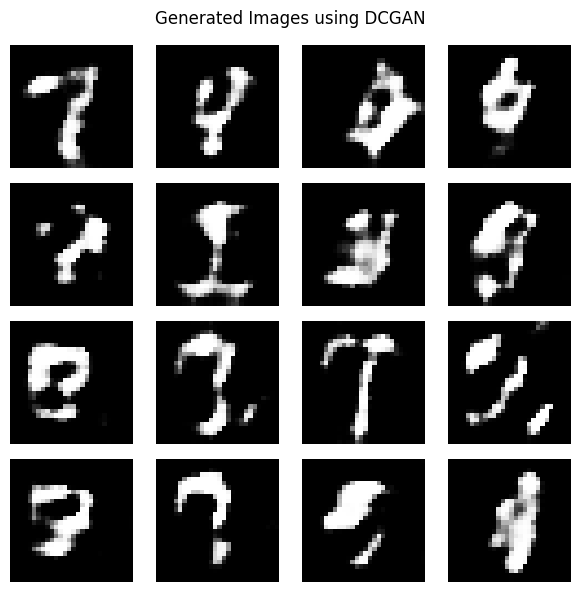

Generated images saved successfully.
Result: A DCGAN model was trained to generate handwritten digit-like images using the MNIST dataset.


In [1]:
# Experiment No. 12
# Image Generation using DCGAN

# 1. Import required libraries
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np

# 2. Load MNIST dataset
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

# Normalize images between -1 and 1
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

print("Training images:", x_train.shape)

# 3. Create dataset batches
BATCH_SIZE = 256
BUFFER_SIZE = 60000
NOISE_DIM = 100

dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE, drop_remainder=True)

# 4. Create Generator
generator = tf.keras.Sequential([
    layers.Input(shape=(NOISE_DIM,)),
    layers.Dense(7 * 7 * 128),
    layers.LeakyReLU(),
    layers.Reshape((7, 7, 128)),

    layers.Conv2DTranspose(
        64, 4, strides=2, padding="same"
    ),
    layers.LeakyReLU(),

    layers.Conv2DTranspose(
        1, 4, strides=2,
        padding="same",
        activation="tanh"
    )
])

# 5. Create Discriminator
discriminator = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        64, 4, strides=2, padding="same"
    ),
    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Conv2D(
        128, 4, strides=2, padding="same"
    ),
    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(1)
])

# 6. Define loss function and optimizers
loss_function = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

generator_optimizer = tf.keras.optimizers.Adam(0.0002)
discriminator_optimizer = tf.keras.optimizers.Adam(0.0002)

# 7. Define training step
@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal([batch_size, NOISE_DIM])

    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        fake_images = generator(noise, training=True)

        real_output = discriminator(
            real_images, training=True
        )
        fake_output = discriminator(
            fake_images, training=True
        )

        gen_loss = loss_function(
            tf.ones_like(fake_output),
            fake_output
        )

        real_loss = loss_function(
            tf.ones_like(real_output),
            real_output
        )

        fake_loss = loss_function(
            tf.zeros_like(fake_output),
            fake_output
        )

        disc_loss = real_loss + fake_loss

    gradients_gen = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    gradients_disc = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(gradients_gen, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(gradients_disc, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss

# 8. Train GAN
EPOCHS = 10

for epoch in range(EPOCHS):
    for image_batch in dataset:
        gen_loss, disc_loss = train_step(image_batch)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} completed | "
        f"Generator Loss: {gen_loss:.4f} | "
        f"Discriminator Loss: {disc_loss:.4f}"
    )

print("GAN Training Completed")

# 9. Generate 16 new images
noise = tf.random.normal([16, NOISE_DIM])
generated_images = generator(noise, training=False)

# 10. Display generated images
plt.figure(figsize=(6, 6))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    image = generated_images[i, :, :, 0]
    plt.imshow(image, cmap="gray", vmin=-1, vmax=1)
    plt.axis("off")

plt.suptitle("Generated Images using DCGAN")
plt.tight_layout()
plt.show()

# 11. Save generated images
images_to_save = (
    (generated_images.numpy() + 1) * 127.5
).clip(0, 255).astype("uint8")

for i in range(16):
    plt.imsave(
        f"/content/generated_digit_{i + 1}.png",
        images_to_save[i, :, :, 0],
        cmap="gray",
        vmin=0,
        vmax=255
    )

print("Generated images saved successfully.")

# 12. Result
print(
    "Result: A DCGAN model was trained to generate "
    "handwritten digit-like images using the MNIST dataset."
)